# 선형 회귀 모델링

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

from sklearn.metrics import mean_squared_error

In [2]:
# CSV 파일로부터 데이터 로드
data = pd.read_csv('new.csv')

# 결과가 0인 값을 5.5로 대체
data['result'] = data['result'].replace(0, 5.5)

# 등급별로 다른 가중치 적용
data['result'] = data.apply(lambda row: row['result'] + 6 if row['GRAD_MDAT_CURNT_NM'] == 1
                            else row['result'] + 3 if row['GRAD_MDAT_CURNT_NM'] == 2 else row['result'], axis=1)

# 독립 변수: 나이, 승률, 연대율, 삼연대율, 평균득점광명, 평균득점종합
X = data[['AGE_CO', 'VICTRY_RT', 'YUNDAE_RT', 'THREE_YUNDAE_RT', 'AVRG_GTSR_TMS3_VALUE', 'AVRG_GTSR_GNRLZ_VALUE']]

# 종속 변수: 결과
y = data['result']

# 데이터 전처리: 스케일링
scaler = StandardScaler()
X = scaler.fit_transform(X)

# 훈련용(80%)과 테스트용(20%) 데이터로 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 선형 회귀 모델 생성
model = LinearRegression()

# 모델 학습
model.fit(X_train, y_train)

C:\Users\USER\anaconda3\lib\site-packages\sklearn\utils\validation.py:623: FutureWarning: is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
  if not hasattr(array, "sparse") and array.dtypes.apply(is_sparse).any():
C:\Users\USER\anaconda3\lib\site-packages\sklearn\utils\validation.py:623: FutureWarning: is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
  if not hasattr(array, "sparse") and array.dtypes.apply(is_sparse).any():


LinearRegression()

In [3]:
# 모델 평가 (예: R-squared)
y_pred = model.predict(X_test)

r_squared = model.score(X_test, y_test)
print(f'R-squared: {r_squared}')

# 모델 성능 평가 (예시로 평균 제곱 오차 사용)
mse = mean_squared_error(y_test, y_pred)
print(f"평균 제곱 오차: {mse}")

R-squared: 0.7196944528204325
평균 제곱 오차: 2.431433475871154


In [4]:
# 23.10.09 광명5 경주
new_players = pd.DataFrame({
    'AGE_CO': [40, 43, 37, 26, 36, 43, 43,],                                                   #나이
    'VICTRY_RT': [53, 30, 31, 34, 54, 15, 33,],                                                #승률
    'YUNDAE_RT': [73, 36, 48, 55, 54, 21, 63,],                                                #연대율
    'THREE_YUNDAE_RT': [87, 41, 67, 74, 56, 23, 81],                                           #삼연대율

    'AVRG_GTSR_TMS3_VALUE': [89.14, 88.68, 88.48, 89.13, 89.56, 89.22, 87.74],                 #평균득점광명
    'AVRG_GTSR_GNRLZ_VALUE':[89.14, 88.02, 89.08, 88.99, 90.31, 88.38, 88.12]                  #평균득점종합   
    
})

# 모델을 사용하여 예측
predicted_ranks = model.predict(new_players)


# 모델로 예측한 결과를 정렬
sorted_ranks = np.argsort(predicted_ranks)

# 정렬된 예상 등수 출력
for i, idx in enumerate(sorted_ranks):
    rank = predicted_ranks[idx]
    player_name = new_players['이름'][idx] if '이름' in new_players else f'선수{idx + 1}'  # 이름이 있는 경우 사용
    print(f'예상 {i + 1}등: {player_name} (예측 점수: {rank:.2f})')

예상 1등: 선수5 (예측 점수: -211.22)
예상 2등: 선수1 (예측 점수: -209.53)
예상 3등: 선수4 (예측 점수: -207.87)
예상 4등: 선수3 (예측 점수: -205.46)
예상 5등: 선수7 (예측 점수: -203.91)
예상 6등: 선수2 (예측 점수: -201.99)
예상 7등: 선수6 (예측 점수: -200.47)


C:\Users\USER\anaconda3\lib\site-packages\sklearn\base.py:443: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(
C:\Users\USER\anaconda3\lib\site-packages\sklearn\utils\validation.py:623: FutureWarning: is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
  if not hasattr(array, "sparse") and array.dtypes.apply(is_sparse).any():


# 선형성 및 상관관계 검증

In [5]:
# 한글 폰트 설정
import matplotlib
import matplotlib.font_manager as fm

fm.get_fontconfig_fonts()
font_location = 'C:/Windows/Fonts/malgun.ttf'
 # For Windows
font_name = fm.FontProperties(fname=font_location).get_name()
matplotlib.rc('font', family=font_name)

C:\Users\USER\AppData\Local\Temp\ipykernel_1776\1044440581.py:5: MatplotlibDeprecationWarning: 
The get_fontconfig_fonts function was deprecated in Matplotlib 3.5 and will be removed two minor releases later.
  fm.get_fontconfig_fonts()


In [12]:
columns_to_drop = ['OPER_INSTT_NM', 'COLOR_NM', 'RACE_DE','PLAYER_NM']
data.drop(columns_to_drop, axis=1, inplace=True)

data.head()

,BASE_YEAR,TME_VALUE,DAY_ORD_VALUE,RACE_NO,BACK_NO,AGE_CO,VICTRY_RT,YUNDAE_RT,THREE_YUNDAE_RT,GRAD_MDAT_CURNT_NM,GRAD_MDAT_BEFORE_NM,AVRG_GTSR_TMS3_VALUE,AVRG_GTSR_GNRLZ_VALUE,result
0,2023,13,1,1,1,40,0,0,0,1,1.0,84.229,84.300,11.5
1,2023,13,1,1,2,50,0,0,20,1,1.0,85.569,85.043,11.5
2,2023,13,1,1,3,39,50,57,71,1,1.0,87.759,88.282,9.0
3,2023,13,1,1,4,41,0,0,0,1,1.0,85.431,83.984,11.5
4,2023,13,1,1,5,49,0,40,40,1,1.0,86.063,86.383,11.5


C:\Users\USER\anaconda3\lib\site-packages\seaborn\utils.py:95: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  fig.canvas.draw()
C:\Users\USER\anaconda3\lib\site-packages\IPython\core\pylabtools.py:151: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


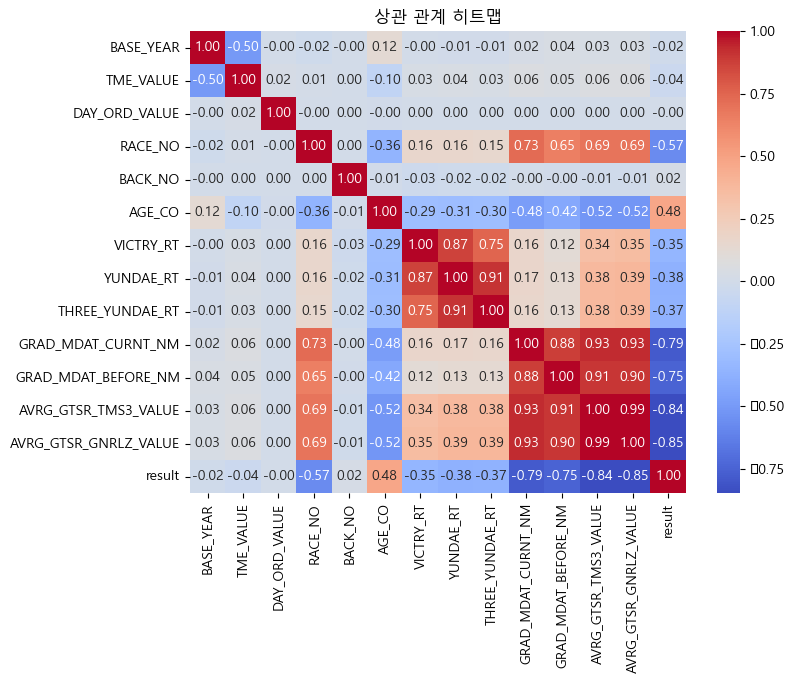

In [13]:
# 상관 행렬 계산
correlation_matrix = data.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")

plt.title('상관 관계 히트맵')
plt.show()

### 나이

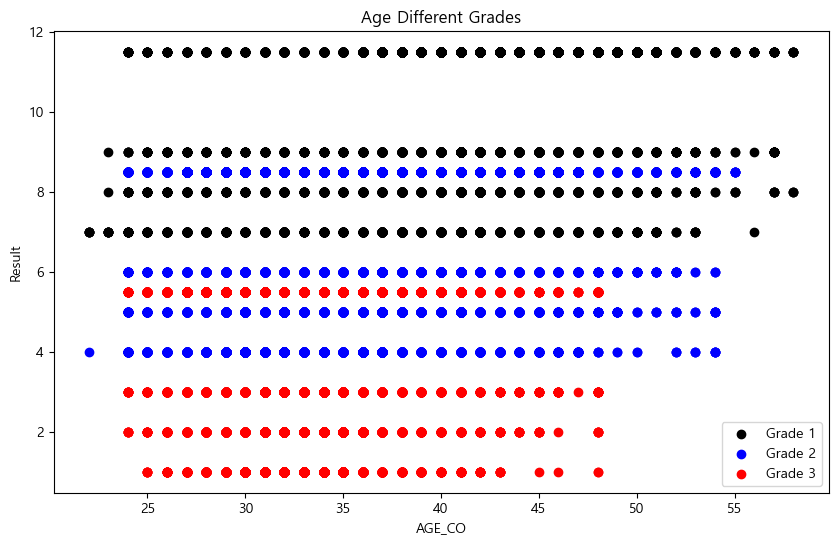

In [14]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler


# 산점도 그리기
plt.figure(figsize=(10, 6))

# 각 등급별로 산점도 그리기
for grade in range(1, 4):
    # 등급에 해당하는 데이터 추출
    grade_data = data[data['GRAD_MDAT_CURNT_NM'] == grade]
    
    # 해당 등급의 독립 변수와 종속 변수
    X_grade = grade_data[['AGE_CO', 'VICTRY_RT', 'YUNDAE_RT', 'THREE_YUNDAE_RT', 'AVRG_GTSR_TMS3_VALUE', 'AVRG_GTSR_GNRLZ_VALUE']]
    y_grade = grade_data['result']
    
    # 색상 설정
    if grade == 1:
        color = 'black'
    elif grade == 2:
        color = 'blue'
    else:
        color = 'red'
    
    # 산점도 그리기
    plt.scatter(X_grade['AGE_CO'], y_grade, color=color, label=f'Grade {grade}')
    
plt.xlabel('AGE_CO')
plt.ylabel('Result')
plt.legend()
plt.title('Age Different Grades')
plt.show()

### 승률

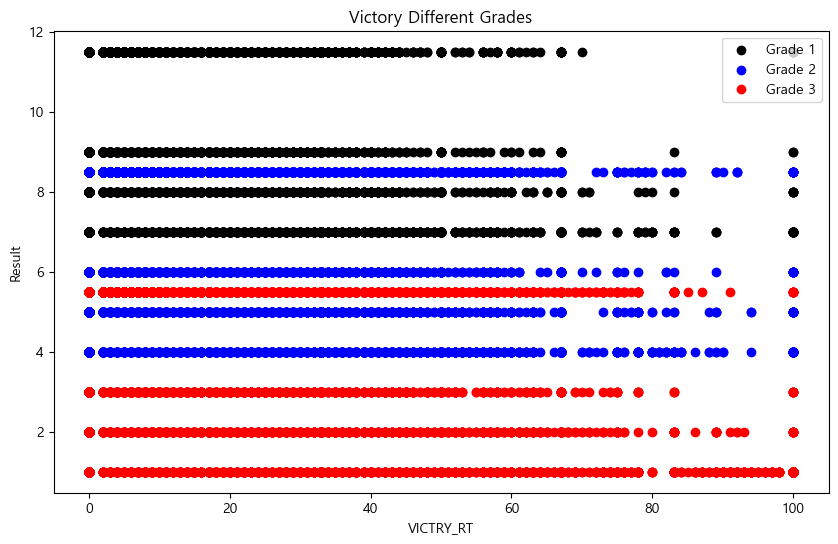

In [15]:
# 산점도 그리기
plt.figure(figsize=(10, 6))

# 각 등급별로 산점도 그리기
for grade in range(1, 4):
    # 등급에 해당하는 데이터 추출
    grade_data = data[data['GRAD_MDAT_CURNT_NM'] == grade]
    
    # 해당 등급의 독립 변수와 종속 변수
    X_grade = grade_data[['AGE_CO', 'VICTRY_RT', 'YUNDAE_RT', 'THREE_YUNDAE_RT', 'AVRG_GTSR_TMS3_VALUE', 'AVRG_GTSR_GNRLZ_VALUE']]
    y_grade = grade_data['result']
    
    # 색상 설정
    if grade == 1:
        color = 'black'
    elif grade == 2:
        color = 'blue'
    else:
        color = 'red'
    
    # 산점도 그리기
    plt.scatter(X_grade['VICTRY_RT'], y_grade, color=color, label=f'Grade {grade}')
    
plt.xlabel('VICTRY_RT')
plt.ylabel('Result')
plt.legend()
plt.title('Victory Different Grades')
plt.show()

### 연대율

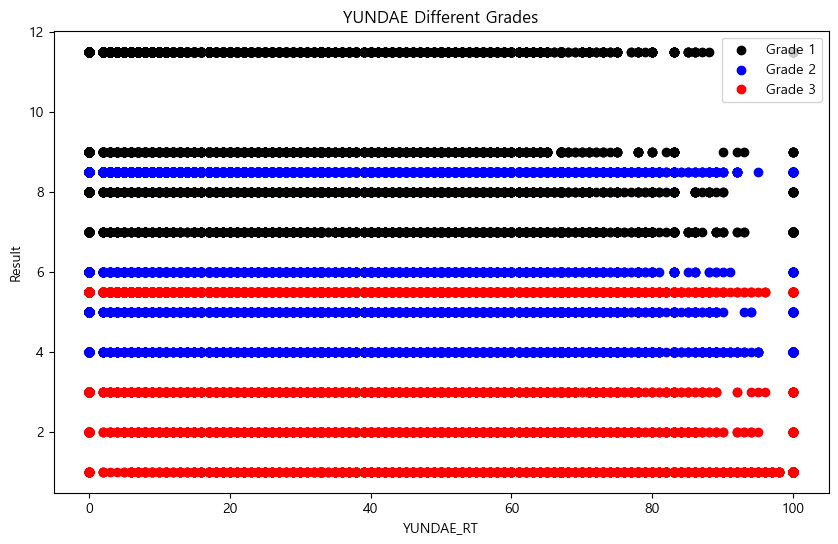

In [16]:
# 산점도 그리기
plt.figure(figsize=(10, 6))

# 각 등급별로 산점도 그리기
for grade in range(1, 4):
    # 등급에 해당하는 데이터 추출
    grade_data = data[data['GRAD_MDAT_CURNT_NM'] == grade]
    
    # 해당 등급의 독립 변수와 종속 변수
    X_grade = grade_data[['AGE_CO', 'VICTRY_RT', 'YUNDAE_RT', 'THREE_YUNDAE_RT', 'AVRG_GTSR_TMS3_VALUE', 'AVRG_GTSR_GNRLZ_VALUE']]
    y_grade = grade_data['result']
    
    # 색상 설정
    if grade == 1:
        color = 'black'
    elif grade == 2:
        color = 'blue'
    else:
        color = 'red'
    
    # 산점도 그리기
    plt.scatter(X_grade['YUNDAE_RT'], y_grade, color=color, label=f'Grade {grade}')
    
    
plt.xlabel('YUNDAE_RT')
plt.ylabel('Result')
plt.legend()
plt.title('YUNDAE Different Grades')
plt.show()

### 삼연대율

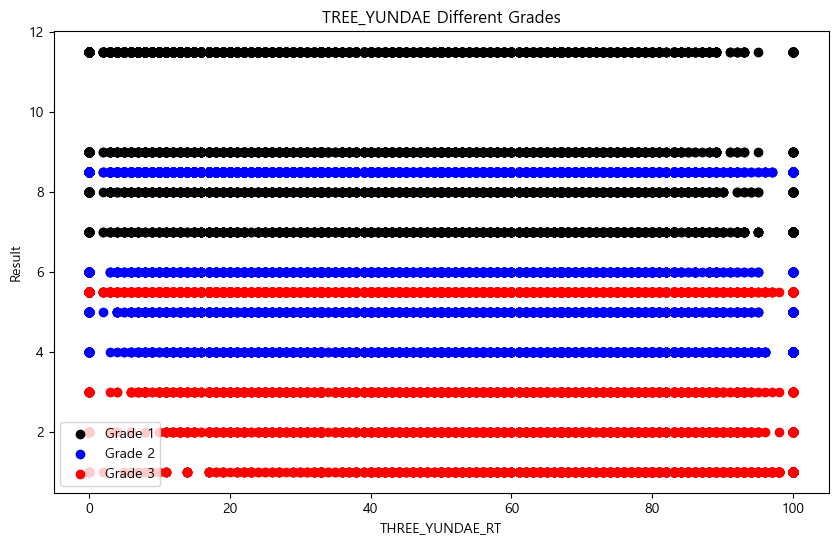

In [17]:
# 산점도 그리기
plt.figure(figsize=(10, 6))

# 각 등급별로 산점도 그리기
for grade in range(1, 4):
    # 등급에 해당하는 데이터 추출
    grade_data = data[data['GRAD_MDAT_CURNT_NM'] == grade]
    
    # 해당 등급의 독립 변수와 종속 변수
    X_grade = grade_data[['AGE_CO', 'VICTRY_RT', 'YUNDAE_RT', 'THREE_YUNDAE_RT', 'AVRG_GTSR_TMS3_VALUE', 'AVRG_GTSR_GNRLZ_VALUE']]
    y_grade = grade_data['result']
    
    # 색상 설정
    if grade == 1:
        color = 'black'
    elif grade == 2:
        color = 'blue'
    else:
        color = 'red'
    
    # 산점도 그리기
    plt.scatter(X_grade['THREE_YUNDAE_RT'], y_grade, color=color, label=f'Grade {grade}')
    
    
plt.xlabel('THREE_YUNDAE_RT')
plt.ylabel('Result')
plt.legend()
plt.title('TREE_YUNDAE Different Grades')
plt.show()

### 평균득점광명

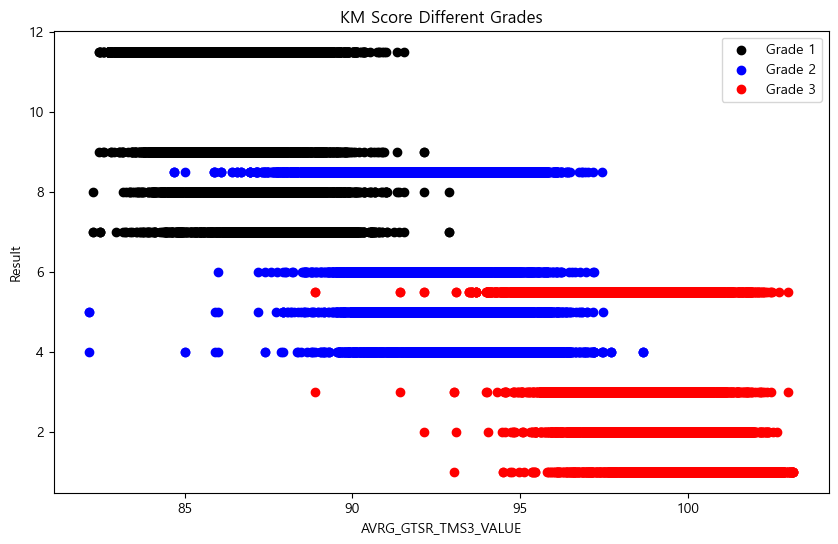

In [18]:
# 산점도 그리기
plt.figure(figsize=(10, 6))

# 각 등급별로 산점도 그리기
for grade in range(1, 4):
    # 등급에 해당하는 데이터 추출
    grade_data = data[data['GRAD_MDAT_CURNT_NM'] == grade]
    
    # 해당 등급의 독립 변수와 종속 변수
    X_grade = grade_data[['AGE_CO', 'VICTRY_RT', 'YUNDAE_RT', 'THREE_YUNDAE_RT', 'AVRG_GTSR_TMS3_VALUE', 'AVRG_GTSR_GNRLZ_VALUE']]
    y_grade = grade_data['result']
    
    # 색상 설정
    if grade == 1:
        color = 'black'
    elif grade == 2:
        color = 'blue'
    else:
        color = 'red'
    
    # 산점도 그리기
    plt.scatter(X_grade['AVRG_GTSR_TMS3_VALUE'], y_grade, color=color, label=f'Grade {grade}')
    
    
plt.xlabel('AVRG_GTSR_TMS3_VALUE')
plt.ylabel('Result')
plt.legend()
plt.title('KM Score Different Grades')
plt.show()

### 평균득점종합

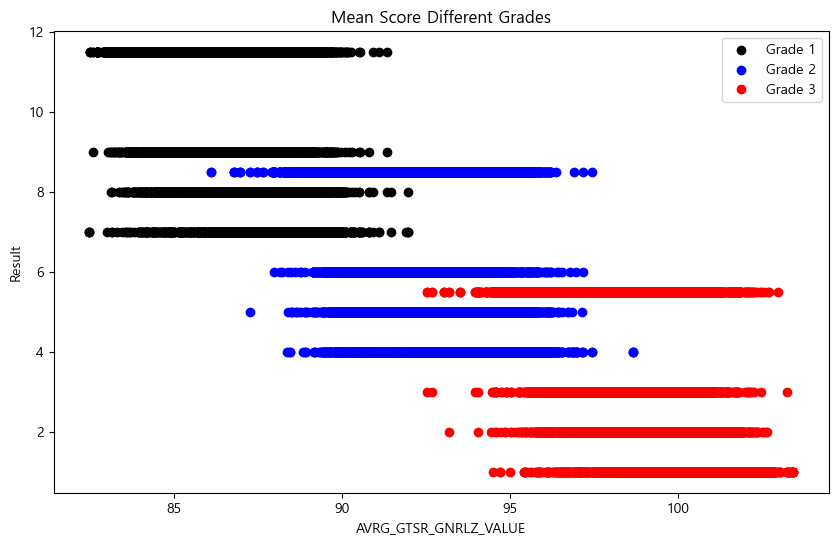

In [19]:
# 산점도 그리기
plt.figure(figsize=(10, 6))

# 각 등급별로 산점도 그리기
for grade in range(1, 4):
    # 등급에 해당하는 데이터 추출
    grade_data = data[data['GRAD_MDAT_CURNT_NM'] == grade]
    
    # 해당 등급의 독립 변수와 종속 변수
    X_grade = grade_data[['AGE_CO', 'VICTRY_RT', 'YUNDAE_RT', 'THREE_YUNDAE_RT', 'AVRG_GTSR_TMS3_VALUE', 'AVRG_GTSR_GNRLZ_VALUE']]
    y_grade = grade_data['result']
    
    # 색상 설정
    if grade == 1:
        color = 'black'
    elif grade == 2:
        color = 'blue'
    else:
        color = 'red'
    
    # 산점도 그리기
    plt.scatter(X_grade['AVRG_GTSR_GNRLZ_VALUE'], y_grade, color=color, label=f'Grade {grade}')
    
    
plt.xlabel('AVRG_GTSR_GNRLZ_VALUE')
plt.ylabel('Result')
plt.legend()
plt.title('Mean Score Different Grades')
plt.show()